<a href="https://colab.research.google.com/github/ShreyasRamchandraDure/BIS_Lab/blob/main/ParallelCellular.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PSNR of Noisy Image: 20.57 dB
PSNR of Denoised Image: 27.71 dB


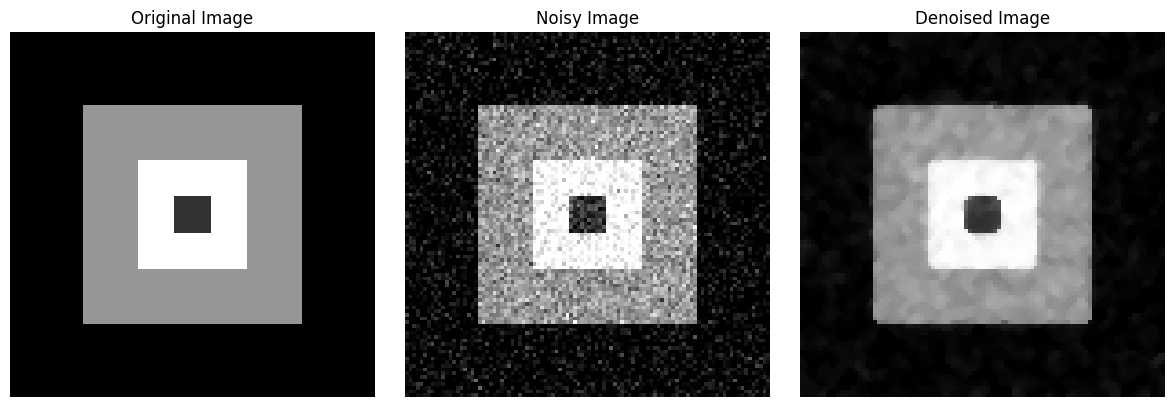

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Create a sample grayscale image
image = np.zeros((100, 100))

image[20:80, 20:80] = 150
image[35:65, 35:65] = 255
image[45:55, 45:55] = 50

# Add Gaussian noise
noise = np.random.normal(0, 30, image.shape)
noisy_image = np.clip(image + noise, 0, 255)

# Parallel Cellular Algorithm
def denoise(img, iterations=5):
    current = img.copy()

    for _ in range(iterations):
        padded = np.pad(current, 1, mode='edge')

        # Collect 3x3 neighborhood values
        neighbors = [
            padded[i:i+100, j:j+100]
            for i in range(3)
            for j in range(3)
        ]

        # All cells update simultaneously
        local_median = np.median(neighbors, axis=0)

        current = 0.5 * current + 0.5 * local_median

    return current

# Apply denoising
denoised_image = denoise(noisy_image)

# PSNR calculation
def psnr(original, result):
    mse = np.mean((original - result) ** 2)

    if mse == 0:
        return float("inf")

    return 10 * np.log10(255 ** 2 / mse)

print("PSNR of Noisy Image:", round(psnr(image, noisy_image), 2), "dB")
print("PSNR of Denoised Image:", round(psnr(image, denoised_image), 2), "dB")

# Display images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy_image, cmap='gray', vmin=0, vmax=255)
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(denoised_image, cmap='gray', vmin=0, vmax=255)
plt.title("Denoised Image")
plt.axis("off")

plt.tight_layout()
plt.show()